# Chimanimani Stage 4 v3 — Validation against the published Idai inventory

**Standalone notebook.** Reads MintPy outputs (`chimanimani_mintpy_run1`) and Stage 3 results
(`chimanimani_stage3`) from Google Drive; keeps inventory files in `chimanimani_inventory` on Drive.
Cells 1 and 2 are v2 (Cell 2 gains a susceptibility clean-up step). Cells 3-6 are rewritten.

## Changes in v3 (all from a review of v2)

| Issue in v2 | Fix in v3 |
|---|---|
| Block "permutation" scattered flags pixel-by-pixel inside blocks. That destroys the contiguous cluster geometry of the real flags, so the null is too narrow and p = 0.002 is anti-conservative. The docstring claim that it preserved within-block autocorrelation was wrong. | **Non-wrapping shift test**: the intact flag map is translated over the terrain by a random offset of at least 3 km; only overlapping, eligible pixels are compared. 999 permutations; smallest attainable p is printed. |
| Strata were slope x elevation only. Line-of-sight velocity depends on aspect relative to the look direction, and aspect also predicts failure. | Everything reported with **and without aspect-quadrant strata**. |
| Published susceptibility gave AUC 0.500 +/- 0.000 (constant predictions), explained as scale mismatch. Raster has float32 overflow values. | Values with abs > 1e6 masked in Cell 2; winsorised at 0.5/99.5 pct in Cell 5; warning if any model returns exactly constant predictions. |
| Rows were dropped globally for missing susceptibility (0 positives, 25 % of negatives), so M0/M1 sampling depended on the published map's footprint. | Rows dropped **per model**. Added M4 (InSAR only). |
| Unconfirmed source pixels were used as controls in the "confirmed" comparison. | They are dropped from that comparison. |
| TS row (14 pixels, OR = 0) counted in the "80 % stable" figure. | Degenerate rows listed but excluded; stability reported over the 18-row detector grid, per strata definition. |
| AOI change presented only as a fix. | CAVEAT string and report block state that the AOI is inventory-derived and was adopted after v1 gave p = 0.076. |

## Caveats to carry into any report

- **Temporal gap** — Inventory: March 2019 (Cyclone Idai). InSAR: Oct 2025 – Sep 2026 (≈ 6-year gap).
  Retrospective coincidence test; it does not test whether InSAR would have predicted the 2019 failures.
- **Scale mismatch** — Median 2019 depletion-zone scar ≈ 600 m²; one InSAR pixel ≈ 1 600 m². Hillslope scale only.
- Report the MH-OR with its CI **and** the permutation p **and** the sensitivity table together.
- The shift test still assumes no regional trend shared by flags and landslides beyond what the strata remove.

In [ ]:

# Google Colab: download the current notebook (.ipynb) to your phone
import json
import datetime
from google.colab import files, _message

# Get the current notebook as JSON
nb_json = _message.blocking_request('get_ipynb', timeout_sec=10)['ipynb']

# Make a filename with date/time
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"Colab_Notebook_{stamp}.ipynb"

# Save it inside the Colab VM
with open(filename, 'w', encoding='utf-8') as f:
    json.dump(nb_json, f, ensure_ascii=False, indent=1)

# Trigger download to your device
files.download(filename)

In [ ]:
# ===== CELL 1: setup, helpers, load MintPy and Stage 3 =====
import os, sys, glob, shutil, subprocess, zipfile, time
import numpy as np, pandas as pd, h5py
from scipy import ndimage
import matplotlib.pyplot as plt

def _ensure(pkg, mod):
    try: __import__(mod)
    except ImportError: subprocess.run([sys.executable,'-m','pip','install','-q',pkg], check=True)
for _p,_m in (('geopandas','geopandas'),('rasterio','rasterio'),('scikit-learn','sklearn'),
              ('requests','requests'),('pyproj','pyproj'),('shapely','shapely')):
    _ensure(_p, _m)
import geopandas as gpd, rasterio, requests
from rasterio import features
from rasterio.transform import Affine
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from shapely.geometry import MultiPoint
from matplotlib.colors import LightSource

# ── CONFIG ────────────────────────────────────────────────────────────────
DRIVE_ROOT      = '/content/drive/MyDrive'
MINTPY_FOLDER   = 'chimanimani_mintpy_run1'
STAGE3_FOLDER   = 'chimanimani_stage3'
OUT_DIR         = '/content/data/stage4v2'
MIN_COH         = 0.7
K_VEL           = 2.5
BG_BLOCK_PX     = 50
MIN_PIXELS      = 20
SLOPE_MIN_DEG   = 5.0
MIN_RUN         = 3          # may be auto-lowered in Cell 3 if needed
MIN_PIXELS_TS   = 10
BUFFER_PX       = 3
BLOCK_CV_PX     = 50
HULL_BUFFER_M   = 5000       # NEW: buffer (m) around inventory convex hull
SEED            = 42

def ok(m):   print(f"[PASS] {m}")
def warn(m): print(f"[WARN] {m}")
def fail(m):
    print(f"[FAIL] {m}")
    raise RuntimeError("STOPPED: " + m)

os.makedirs(OUT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

# ── Drive helpers ─────────────────────────────────────────────────────────
def mount_drive():
    if os.path.isdir(DRIVE_ROOT): return True
    try:
        from google.colab import drive
        drive.mount(os.path.dirname(DRIVE_ROOT))
    except Exception as e:
        warn(f"Could not mount Drive ({type(e).__name__}: {e})")
    return os.path.isdir(DRIVE_ROOT)

def walk_drive(match, max_depth=8, max_seconds=240):
    t0, hits = time.time(), []
    base_depth = DRIVE_ROOT.rstrip('/').count('/')
    for dp, dn, fn in os.walk(DRIVE_ROOT):
        dn[:] = [d for d in dn if not d.startswith('.')]
        if dp.count('/') - base_depth >= max_depth: dn[:] = []
        if match(dp, fn): hits.append((dp, fn))
        if time.time()-t0 > max_seconds:
            warn(f"Drive search stopped after {max_seconds} s"); break
    return hits

def find_folder(name, required):
    if not mount_drive(): fail("Google Drive not available")
    complete = lambda d: all(os.path.exists(os.path.join(d,f)) for f in required)
    direct = os.path.join(DRIVE_ROOT, name)
    if complete(direct): return direct
    print(f"Searching Drive for '{name}' ...")
    hits = [dp for dp,_ in walk_drive(
        lambda dp,fn: os.path.basename(dp)==name and complete(dp))]
    if not hits: fail(f"No folder '{name}' with {required} found in Drive")
    return hits[0]

# ── Data helpers ──────────────────────────────────────────────────────────
def read_h5(path, name):
    with h5py.File(path,'r') as f:
        if name not in f: fail(f"Dataset '{name}' missing from {path}. Keys: {list(f.keys())}")
        return f[name][:], {k:(v.decode() if isinstance(v,bytes) else v) for k,v in f.attrs.items()}

def mad_sigma(x):
    x = x[np.isfinite(x)]
    return 1.4826 * np.median(np.abs(x - np.median(x)))

def terrain(h, xs, ys):
    dzdx = np.gradient(h, axis=1) / xs
    dzdy = np.gradient(h, axis=0) / ys
    slope  = np.degrees(np.arctan(np.hypot(dzdx, dzdy)))
    aspect = np.degrees(np.arctan2(-dzdx, -dzdy)) % 360
    curv   = np.gradient(dzdx, axis=1)/xs + np.gradient(dzdy, axis=0)/ys
    return slope, aspect, curv

def block_background(field, valid, block):
    ny, nx = field.shape
    by, bx = -(-ny//block), -(-nx//block)
    coarse  = np.full((by,bx), np.nan)
    for i in range(by):
        for j in range(bx):
            sl = (slice(i*block,(i+1)*block), slice(j*block,(j+1)*block))
            v  = field[sl][valid[sl]]
            if v.size >= max(10, 0.05*block*block): coarse[i,j] = np.median(v)
    if np.isnan(coarse).all(): raise ValueError("No block has enough valid pixels")
    idx    = ndimage.distance_transform_edt(
        np.isnan(coarse), return_distances=False, return_indices=True)
    coarse = ndimage.gaussian_filter(coarse[tuple(idx)], 1.0, mode='nearest')
    yy = (np.arange(ny)+0.5)/block - 0.5
    xx = (np.arange(nx)+0.5)/block - 0.5
    return ndimage.map_coordinates(
        coarse, np.array(np.meshgrid(yy,xx,indexing='ij')), order=1, mode='nearest')

def detect_velocity_clusters(vel_mm, valid, slope, k, block, min_pixels, slope_min):
    bg    = block_background(vel_mm, valid, block)
    resid = np.where(valid, vel_mm - bg, np.nan)
    sigma = mad_sigma(resid[valid])
    z     = resid / sigma
    labels = np.zeros(vel_mm.shape, dtype=np.int32)
    sign   = {}; nxt = 0
    s8 = np.ones((3,3), dtype=int)
    for s in (1,-1):
        cand     = valid & (s*z > k)
        lab, n   = ndimage.label(cand, structure=s8)
        if n == 0: continue
        area     = np.bincount(lab.ravel(), minlength=n+1)
        mean_slp = ndimage.mean(slope, lab, index=np.arange(1,n+1))
        for i in range(1,n+1):
            if area[i] < min_pixels or mean_slp[i-1] < slope_min: continue
            nxt += 1; labels[lab==i] = nxt; sign[nxt] = s
    return dict(labels=labels, sign=sign, z=z, resid=resid, bg=bg, sigma=sigma)

def label_filter(mask, min_pixels):
    lab, n = ndimage.label(mask, structure=np.ones((3,3), dtype=int))
    if n == 0: return np.zeros(mask.shape, dtype=np.int32), 0
    area = np.bincount(lab.ravel(), minlength=n+1)
    keep = np.zeros(n+1, dtype=np.int32)
    ids  = [i for i in range(1,n+1) if area[i] >= min_pixels]
    keep[ids] = np.arange(1, len(ids)+1)
    return keep[lab], len(ids)

def dilate(mask, n):
    return (ndimage.binary_dilation(mask, structure=np.ones((3,3),dtype=bool), iterations=n)
            if n > 0 else mask)

# ── Load MintPy ───────────────────────────────────────────────────────────
MINTPY_DIR = find_folder(MINTPY_FOLDER,
    ['velocity.h5','temporalCoherence.h5','inputs/geometryGeo.h5'])
STAGE3_DIR = find_folder(STAGE3_FOLDER, ['ts_anomaly_dates.tif'])
ok(f"MintPy  : {MINTPY_DIR}")
ok(f"Stage 3 : {STAGE3_DIR}")

vel,    vattr = read_h5(f'{MINTPY_DIR}/velocity.h5',           'velocity')
tcoh,   _     = read_h5(f'{MINTPY_DIR}/temporalCoherence.h5', 'temporalCoherence')
height, _     = read_h5(f'{MINTPY_DIR}/inputs/geometryGeo.h5','height')
wmask,  _     = read_h5(f'{MINTPY_DIR}/inputs/geometryGeo.h5','waterMask')
if len({vel.shape,tcoh.shape,height.shape,wmask.shape}) != 1:
    fail("MintPy layers differ in grid size")
ok(f"MintPy grid {vel.shape}")

x_step, y_step = float(vattr['X_STEP']), float(vattr['Y_STEP'])
x0,     y0     = float(vattr['X_FIRST']), float(vattr['Y_FIRST'])
if abs(x_step) < 1: fail("Grid appears to be in degrees; a projected (m) grid is required")
if np.nanmedian(np.abs(vel)) > 1: fail("Velocity units look wrong (expected m/yr; values suggest mm/yr)")

vel_mm = vel * 1000.0
water  = ~wmask.astype(bool)
if water.mean() > 0.5: fail("waterMask looks inverted")
valid  = (np.isfinite(vel_mm) & np.isfinite(height) & np.isfinite(tcoh)
          & (tcoh >= MIN_COH) & ~water)
ny_g, nx_g = vel.shape
print(f"Usable pixels: {valid.sum():,} / {valid.size:,} ({valid.mean():.0%})")
if valid.mean() < 0.20: fail("Fewer than 20 % of pixels are usable")

# Stage 3 grid consistency check
with rasterio.open(os.path.join(STAGE3_DIR,'ts_anomaly_dates.tif')) as src:
    nflag = src.read(1).astype('float32')
    tr3, crs3 = src.transform, src.crs
epsg = crs3.to_epsg() if crs3 is not None else None
if epsg is None: fail("Stage 3 GeoTIFF has no EPSG code")
if nflag.shape != vel.shape:
    fail(f"Stage 3 grid {nflag.shape} != MintPy grid {vel.shape}")
if not (abs(tr3.a-x_step)<1e-6 and abs(tr3.e-y_step)<1e-6
        and abs(tr3.c-x0)<1e-3  and abs(tr3.f-y0)<1e-3):
    fail("Stage 3 GeoTIFF geotransform differs from the MintPy grid")
ok(f"Stage 3 grid OK; CRS EPSG:{epsg}")

transform = Affine(x_step, 0, x0, 0, y_step, y0)

# Terrain
slope, aspect, curv = terrain(
    np.where(np.isfinite(height), height, np.nanmedian(height)), x_step, y_step)

# Velocity clusters (reproduce Stage 3)
A    = detect_velocity_clusters(vel_mm, valid, slope, K_VEL, BG_BLOCK_PX, MIN_PIXELS, SLOPE_MIN_DEG)
n_cl = len(A['sign'])
print(f"Velocity detector: sigma {A['sigma']:.1f} mm/yr, {n_cl} clusters")
csv3 = os.path.join(STAGE3_DIR,'velocity_clusters.csv')
if os.path.exists(csv3):
    n3 = len(pd.read_csv(csv3))
    (ok if n3==n_cl else warn)(
        f"Reproduces Stage 3 ({n_cl} clusters vs {n3} saved)")
else:
    warn("velocity_clusters.csv not found in Stage 3 folder: reproduction check skipped")

# Hillshade for plots
hs = LightSource(azdeg=315, altdeg=45).hillshade(
    np.where(np.isfinite(height), height, np.nanmedian(height)),
    vert_exag=2, dx=abs(x_step), dy=abs(y_step))

Mounted at /content/drive
[PASS] MintPy  : /content/drive/MyDrive/chimanimani_mintpy_run1
[PASS] Stage 3 : /content/drive/MyDrive/chimanimani_stage3
[PASS] MintPy grid (905, 1002)
Usable pixels: 724,366 / 906,810 (80%)
[PASS] Stage 3 grid OK; CRS EPSG:32736
Velocity detector: sigma 10.2 mm/yr, 718 clusters
[PASS] Reproduces Stage 3 (718 clusters vs 718 saved)


In [ ]:
# ===== CELL 2: inventory files, quality check, AOI mask, TS diagnostics =====
#
# Key additions vs Stage 4 v1:
#   * Inventory convex hull + buffer → elig_clipped (used in all later cells)
#   * TS anomaly diagnostic table + auto MIN_RUN lowering

EXTENT_CLASS_FIELD  = 'Zone'
SOURCE_CLASS_VALUES = ['Depletion zone']
INV_BUFFER_M        = 100
INV_DIR             = '/content/data/idai_inventory'
INV_DRIVE_DIR       = os.path.join(DRIVE_ROOT,'chimanimani_inventory')
_BASE = 'https://ihp-wins.unesco.org/dataset/a8ee8e1f-2d15-4bd0-9676-c23bd05d54e0/resource/'
FILES = {
    'points': (
        'idai-landslide-source-points.zip',
        _BASE+'cebae5cf-0b07-49d4-aba0-c8a76358b712/download/idai-landslide-source-points.zip',
        'Landslide SOURCE POINTS shapefile (zip)'),
    'extent': (
        'idai-landslide-extent-maps_zones.zip',
        _BASE+'f6178eaa-e0f6-41c0-b81c-1a3c9d1390cd/download/idai-landslide-extent-maps_zones.zip',
        'Landslide EXTENT MAPS shapefile (zip)'),
    'susc': (
        'landslide-susceptibility-map-for-landslide-sources-in-chimanimani-and-chipinge_cog.tif',
        _BASE+'52fab087-d606-41a4-9b12-dffaca3cb925/download/landslide-susceptibility-map-for-landslide-sources-in-chimanimani-and-chipinge_cog.tif',
        'Published susceptibility GeoTIFF'),
}
os.makedirs(INV_DIR, exist_ok=True)
_download_ok = True

def _verify(path):
    if os.path.getsize(path) == 0: return False
    if path.endswith('.zip'):
        with zipfile.ZipFile(path) as z: return z.testzip() is None
    return True

def get_inventory_file(key):
    global _download_ok
    name, url, desc = FILES[key]
    dest = os.path.join(INV_DIR, name)
    if os.path.exists(dest) and _verify(dest):
        ok(f"{name} already on this runtime"); return dest
    drive_copy = os.path.join(INV_DRIVE_DIR, name)
    if mount_drive() and os.path.exists(drive_copy) and _verify(drive_copy):
        shutil.copy(drive_copy, dest); ok(f"{name} copied from Drive"); return dest
    if _download_ok:
        try:
            with requests.get(url, stream=True, timeout=30) as r:
                r.raise_for_status()
                with open(dest,'wb') as f:
                    for chunk in r.iter_content(1<<20): f.write(chunk)
            if not _verify(dest): raise IOError("verification failed")
            ok(f"{name} downloaded")
        except Exception as e:
            _download_ok = False
            if os.path.exists(dest): os.remove(dest)
            warn(f"Download failed ({type(e).__name__}); switching to manual upload")
    if not os.path.exists(dest):
        from google.colab import files
        print(f"\n{'='*72}\n  UPLOAD: {desc}\n  Filename (exact): {name}\n{'='*72}")
        up = files.upload()
        if len(up) != 1: fail(f"Upload exactly one file for '{key}'")
        got = list(up)[0]
        if got != name: fail(f"Expected '{name}', got '{got}' — rename and re-run")
        with open(dest,'wb') as f: f.write(up[got])
        if not _verify(dest): fail(f"{name} is corrupt")
        ok(f"{name} uploaded ({os.path.getsize(dest)/1e6:.1f} MB)")
    if mount_drive():
        os.makedirs(INV_DRIVE_DIR, exist_ok=True)
        shutil.copy(dest, drive_copy)
    return dest

def read_vector(zip_path):
    d = os.path.join(INV_DIR, os.path.basename(zip_path)[:-4])
    if not os.path.isdir(d):
        with zipfile.ZipFile(zip_path) as z: z.extractall(d)
    shps = glob.glob(f'{d}/**/*.shp', recursive=True)
    if len(shps) != 1:
        fail(f"Expected one .shp in {zip_path}, found {len(shps)}: {shps}")
    g = gpd.read_file(shps[0])
    if g.crs is None: fail(f"{shps[0]} has no coordinate system")
    return g[g.geometry.notna() & ~g.geometry.is_empty].copy()

pts_path, ext_path, susc_path = (get_inventory_file(k) for k in ('points','extent','susc'))
G_pts, G_ext = read_vector(pts_path), read_vector(ext_path)
print(f"Source points : {len(G_pts)} features, CRS {G_pts.crs.to_string()}, "
      f"geom {sorted(G_pts.geom_type.unique())}")
print(f"Extent maps   : {len(G_ext)} features, CRS {G_ext.crs.to_string()}, "
      f"fields {[c for c in G_ext.columns if c!='geometry']}")
G_pts, G_ext = G_pts.to_crs(epsg), G_ext.to_crs(epsg)
if not (G_pts.geom_type=='Point').all():
    warn("Non-point geometries present; using centroids")
    G_pts['geometry'] = G_pts.geometry.centroid

px, py    = G_pts.geometry.x.to_numpy(), G_pts.geometry.y.to_numpy()
rows_all  = np.floor((py - y0) / y_step).astype(int)
cols_all  = np.floor((px - x0) / x_step).astype(int)
inside    = (rows_all>=0)&(rows_all<ny_g)&(cols_all>=0)&(cols_all<nx_g)
pr, pc    = rows_all[inside], cols_all[inside]

# ── NEW: inventory AOI mask ───────────────────────────────────────────────
# Build a clipped eligible mask from the convex hull of the inventory points
# plus a generous buffer.  Everything from Cell 3 onward uses elig_clipped,
# not the full-footprint elig, so the null permutation distribution is drawn
# from terrain that was genuinely in or adjacent to the 2019 impact zone.
inv_hull_geom = MultiPoint(list(zip(px[inside], py[inside]))).convex_hull.buffer(HULL_BUFFER_M)
aoi_mask = features.rasterize(
    [(inv_hull_geom, 1)], out_shape=vel.shape, transform=transform,
    fill=0, dtype='uint8').astype(bool)
elig         = valid & (slope >= SLOPE_MIN_DEG)
elig_clipped = elig & aoi_mask

aoi_km2  = aoi_mask.sum() * abs(x_step*y_step) / 1e6
full_km2 = ny_g * nx_g * abs(x_step*y_step) / 1e6
ok(f"Inventory AOI (hull + {HULL_BUFFER_M/1000:.0f} km buffer): {aoi_km2:.0f} km² "
   f"({aoi_km2/full_km2:.0%} of the {full_km2:.0f} km² MintPy footprint)")
print(f"Eligible pixels — full footprint: {elig.sum():,}   "
      f"clipped AOI: {elig_clipped.sum():,} ({elig_clipped.sum()/elig.sum():.0%})")
if elig_clipped.sum() < 10000:
    warn(f"Fewer than 10 000 eligible pixels in the clipped AOI ({elig_clipped.sum():,}); "
         "consider increasing HULL_BUFFER_M")

# ── Point-level quality check ─────────────────────────────────────────────
dups = int(pd.Series(list(zip(
    np.round(px[inside],1), np.round(py[inside],1)))).duplicated().sum())
print(f"\nInventory inside grid     : {inside.sum()} of {len(px)} ({dups} exact duplicates)")
print(f"  on usable InSAR pixels  : {int(valid[pr,pc].sum())} ({valid[pr,pc].mean():.0%})")
print(f"  with slope >= {SLOPE_MIN_DEG:.0f} deg   : {int(elig[pr,pc].sum())} ({elig[pr,pc].mean():.0%})")
print(f"  density in AOI          : {inside.sum()/aoi_km2:.1f} pts km-2 over {aoi_km2:.0f} km2")
if inside.sum() < 100: fail("Fewer than 100 inventory points inside the AOI")

# Landslide pixel masks
L = np.zeros(vel.shape, dtype=bool); L[pr, pc] = True
n_L = int((L & elig_clipped).sum())
(ok if n_L >= 100 else warn)(f"{n_L} eligible landslide pixels in the clipped AOI")
if n_L < 30: fail("Fewer than 30 eligible landslide pixels")

# Event-confirmed pixels (within INV_BUFFER_M of a depletion-zone polygon)
fld, vals = EXTENT_CLASS_FIELD, SOURCE_CLASS_VALUES
if fld not in G_ext.columns:
    fail(f"Field '{fld}' not in extent map. Fields: {[c for c in G_ext.columns if c!='geometry']}")
src_polys = G_ext[G_ext[fld].isin(vals)]
if len(src_polys) == 0:
    fail(f"No polygons with {fld} in {vals}. Values present: "
         f"{sorted(G_ext[fld].dropna().unique().tolist(), key=str)}")
ok(f"Source polygons ('{fld}' in {vals}): {len(src_polys)}")
src_mask = features.rasterize(
    ((g,1) for g in src_polys.geometry), out_shape=vel.shape, transform=transform,
    fill=0, all_touched=True, dtype='uint8').astype(bool)
buf_px   = int(np.ceil(INV_BUFFER_M / abs(x_step)))
src_near = ndimage.binary_dilation(src_mask, structure=np.ones((3,3),dtype=bool), iterations=buf_px)
confirmed = src_near[pr, pc]
L_conf = np.zeros(vel.shape, dtype=bool); L_conf[pr[confirmed], pc[confirmed]] = True
print(f"  within {INV_BUFFER_M} m of a source polygon: {confirmed.sum()} of {len(pr)} ({confirmed.mean():.0%})")
print(f"  (paper reports 73.8 % over both districts)")
print(f"  eligible confirmed pixels in clipped AOI: {int((L_conf & elig_clipped).sum())}")

# ── Susceptibility raster ─────────────────────────────────────────────────
with rasterio.open(susc_path) as src:
    nod, dt = src.nodata, src.dtypes[0]
    probe   = src.read(1, out_shape=(max(1,src.height//20), max(1,src.width//20)),
                       resampling=Resampling.nearest)
sample = probe[np.isfinite(probe)]
if nod is not None: sample = sample[sample != nod]
if sample.size == 0: fail("Susceptibility raster sample is empty")
categorical = np.issubdtype(np.dtype(dt),np.integer) or len(np.unique(sample)) <= 12
print(f"\nSusceptibility: dtype {dt}, nodata {nod}, "
      f"range [{sample.min():.3g},{sample.max():.3g}], "
      f"{'categorical (nearest-neighbour)' if categorical else 'continuous (bilinear)'}")
with rasterio.open(susc_path) as src:
    with WarpedVRT(src, crs=f'EPSG:{epsg}', transform=transform, width=nx_g, height=ny_g,
                   resampling=Resampling.nearest if categorical else Resampling.bilinear,
                   nodata=nod) as vrt:
        susc = vrt.read(1).astype('float32')
if nod is not None: susc[susc==nod] = np.nan

# v3: the raster contains float32 overflow artefacts (range reported as -2e38 .. 7e36). The v2 note that these
# "do not affect the analysis" came from a coarse probe of the WHOLE raster, not from the clipped AOI.
SUSC_ABS_MAX = 1e6
_bad = np.isfinite(susc) & (np.abs(susc) > SUSC_ABS_MAX)
print(f"Susceptibility: {int(_bad.sum()):,} pixels with |value| > {SUSC_ABS_MAX:g} set to NaN "
      f"({int((_bad & elig_clipped).sum()):,} inside the clipped AOI)")
susc[_bad] = np.nan
_sv0 = susc[elig_clipped & np.isfinite(susc)]
if _sv0.size:
    print(f"Susceptibility in clipped AOI after cleaning: min {_sv0.min():.4g}, "
          f"median {np.median(_sv0):.4g}, max {_sv0.max():.4g}")
    if _sv0.max() - _sv0.min() > 1e3:
        warn("Susceptibility range is still very wide; inspect the raster before trusting M2/M3")
susc_cov = np.isfinite(susc[elig_clipped]).mean()
(ok if susc_cov >= 0.90 else warn)(
    f"Susceptibility coverage in clipped AOI: {susc_cov:.0%}"
    + ("" if susc_cov >= 0.90 else " — logistic models restricted to covered pixels"))
if susc_cov < 0.50: fail("< 50 % coverage in the clipped AOI; check CRS and grid")

# ── TS anomaly diagnostics ────────────────────────────────────────────────
# In v1 the TS detector produced 4 clusters with 0 eligible pixels
# (all 4 clusters fell on terrain with slope < SLOPE_MIN_DEG or outside
# the valid mask).  Here we:
#   1. Print a diagnostic table across several MIN_RUN values.
#   2. Auto-lower MIN_RUN until we get >= 10 eligible pixels,
#      with a warning if the default threshold cannot be used.
nflag[nflag == -9999] = 0
print(f"\n--- Time-series anomaly diagnostics ---")
print(f"  nflag value range  : {int(nflag.min())} -- {int(nflag.max())}")
print(f"  pixels with nflag > 0 (full grid) : {int((nflag>0).sum())}")
print(f"  {'MIN_RUN':>8}  {'clusters':>10}  {'total px':>10}  {'eligible px (clipped AOI)':>26}")
for mr in sorted(set([1, 2, MIN_RUN])):
    lb_t, n_t = label_filter(nflag >= mr, MIN_PIXELS_TS)
    n_all  = int((lb_t > 0).sum())
    n_elig = int(((lb_t > 0) & elig_clipped).sum())
    print(f"  {mr:>8}  {n_t:>10}  {n_all:>10}  {n_elig:>26}")

# Auto-lower
_mr   = MIN_RUN
_found = False
for trial in range(MIN_RUN, 0, -1):
    lb_t, n_t = label_filter(nflag >= trial, MIN_PIXELS_TS)
    if ((lb_t > 0) & elig_clipped).sum() >= 10:
        _mr = trial; _found = True; break
if not _found:
    _mr = 1
    warn("Even MIN_RUN=1 gives no eligible TS clusters in the clipped AOI; "
         "check ts_anomaly_dates.tif has values in the inventory zone")
if _mr < MIN_RUN:
    warn(f"MIN_RUN automatically lowered {MIN_RUN} -> {_mr} to obtain eligible "
         "TS clusters; review this choice before reporting")
else:
    ok(f"MIN_RUN={MIN_RUN} retained")

lab_B, n_B = label_filter(nflag >= _mr, MIN_PIXELS_TS)
mask_B     = lab_B > 0
ok(f"TS anomaly clusters: {n_B}  "
   f"eligible pixels in clipped AOI: {int((mask_B & elig_clipped).sum())}")
ok("Inventory and benchmark loaded")

[PASS] idai-landslide-source-points.zip copied from Drive
[PASS] idai-landslide-extent-maps_zones.zip copied from Drive
[PASS] landslide-susceptibility-map-for-landslide-sources-in-chimanimani-and-chipinge_cog.tif copied from Drive


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: /content/data/idai_inventory/idai-landslide-extent-maps_zones/Idai Landslide Extent Maps.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


Source points : 14900 features, CRS EPSG:32736, geom ['Point']
Extent maps   : 36026 features, CRS EPSG:4326, fields ['LS_Type4', 'Area', 'ID', 'Zone']
[PASS] Inventory AOI (hull + 5 km buffer): 1129 km² (78% of the 1451 km² MintPy footprint)
Eligible pixels — full footprint: 656,444   clipped AOI: 554,303 (84%)

Inventory inside grid     : 5599 of 14900 (2 exact duplicates)
  on usable InSAR pixels  : 4849 (87%)
  with slope >= 5 deg   : 4835 (86%)
  density in AOI          : 5.0 pts km-2 over 1129 km2
[PASS] 4506 eligible landslide pixels in the clipped AOI
[PASS] Source polygons ('Zone' in ['Depletion zone']): 10846
  within 100 m of a source polygon: 5005 of 5599 (89%)
  (paper reports 73.8 % over both districts)
  eligible confirmed pixels in clipped AOI: 3988

Susceptibility: dtype float32, nodata -99999.0, range [-2.01e+38,6.84e+36], continuous (bilinear)
Susceptibility: 133 pixels with |value| > 1e+06 set to NaN (129 inside the clipped AOI)
Susceptibility in clipped AOI after c

In [ ]:
# ===== CELL 3: primary validation (v3) — clipped AOI, non-wrapping shift test, aspect-adjusted strata =====
#
# Changes vs v2:
#   1. Permutation null. The v2 block permutation scattered flags pixel-by-pixel inside each block, which
#      destroys the contiguous geometry of the real flag clusters and understates null variance (the
#      docstring claim that it "preserves within-block spatial autocorrelation" was incorrect). v3 slides
#      the INTACT flag map over the terrain by a random offset >= MIN_SHIFT_PX with no wrap-around; only
#      pixels whose shifted source lies inside the grid AND was itself eligible are compared.
#   2. Strata. Reported with slope x elevation (as v2) AND slope x elevation x aspect quadrant. Line-of-sight
#      velocity depends on slope aspect relative to the satellite look direction, and aspect also predicts
#      failure, so aspect can confound the flag/landslide association.
#   3. The "confirmed" comparison drops unconfirmed source pixels instead of treating them as controls.
#   4. The smallest attainable permutation p (1 / (n+1)) is printed with every p-value.

from scipy import sparse

N_PERM         = 999
MIN_SHIFT_PX   = 75          # 3 km at 40 m; larger than typical cluster size
rng_shift      = np.random.default_rng(SEED + 1)

# ── 1-D index arrays over clipped-eligible pixels (row-major) ─────────────
er, ec = np.nonzero(elig_clipped)
n_el   = er.size

def _aspect_sector(a):                     # 0=N 1=E 2=S 3=W
    return (((a + 45.0) // 90.0).astype(int)) % 4

def make_strata(slope, height, elig_mask, aspect=None):
    s_bin = np.clip((slope // 2).astype(int), 0, 29)
    e_bin = np.clip(((height - np.nanmin(height[elig_mask])) // 100).astype(int), 0, None)
    code  = s_bin * 1000 + e_bin
    if aspect is not None:
        code = code * 10 + _aspect_sector(aspect)
    uniq, inv = np.unique(code[elig_mask], return_inverse=True)
    return inv.astype(np.int64), len(uniq)

strat_s, S_s = make_strata(slope, height, elig_clipped)
strat_a, S_a = make_strata(slope, height, elig_clipped, aspect)
STRATA = {'slope x elev': (strat_s, S_s),
          'slope x elev x aspect': (strat_a, S_a)}

blk_raw   = ((np.arange(vel.shape[0])[:, None] // BLOCK_CV_PX) * 10000
             + np.arange(vel.shape[1])[None, :] // BLOCK_CV_PX)
ub_c, eb  = np.unique(blk_raw[er, ec], return_inverse=True)
NB_c      = len(ub_c)

print(f"Clipped eligible: {n_el:,} pixels | strata: {S_s} (slope x elev), "
      f"{S_a} (+ aspect quadrant) | {NB_c} spatial blocks of ~{BLOCK_CV_PX*abs(x_step)/1000:.0f} km")
if NB_c < 30: warn(f"Only {NB_c} spatial blocks in clipped AOI — CIs will be wide")

# ── Statistics ────────────────────────────────────────────────────────────
def mh_or_vec(tot):
    """Mantel-Haenszel OR. tot[..., S, 4] = (flag&case, flag&ctrl, ~flag&case, ~flag&ctrl)."""
    a, b, c, d = tot[..., 0], tot[..., 1], tot[..., 2], tot[..., 3]
    n = a + b + c + d
    with np.errstate(divide='ignore', invalid='ignore'):
        num = np.where(n > 0, a * d / n, 0.0).sum(-1)
        den = np.where(n > 0, b * c / n, 0.0).sum(-1)
        return np.where(den > 0, num / den, np.nan)

def _cat(F1, L1):
    return np.where(F1 & L1, 0, np.where(F1 & ~L1, 1, np.where(~F1 & L1, 2, 3)))

def _or_on(F1, L1, strata, S, keep):
    flat = strata[keep] * 4 + _cat(F1, L1)[keep]
    tot  = np.bincount(flat, minlength=S * 4).reshape(S, 4)
    return float(mh_or_vec(tot))

def mh_with_ci(F1, L1, strata, S, keep, n_boot=1000):
    """MH OR with a spatial-block bootstrap CI (blocks resampled with replacement)."""
    cat  = _cat(F1, L1)[keep]
    rows = eb[keep]
    cols = strata[keep] * 4 + cat
    C    = sparse.csr_matrix((np.ones(rows.size), (rows, cols)), shape=(NB_c, S * 4))
    point = float(mh_or_vec(np.asarray(C.sum(0)).reshape(S, 4)))
    reps  = []
    for s0 in range(0, n_boot, 100):
        m   = min(100, n_boot - s0)
        W   = np.stack([np.bincount(rng.integers(0, NB_c, NB_c), minlength=NB_c) for _ in range(m)])
        tot = np.asarray((C.T @ W.T.astype(float)).T).reshape(m, S, 4)
        reps.append(mh_or_vec(tot))
    reps = np.concatenate(reps)
    if np.isfinite(reps).sum() > 20:
        lo, hi = np.nanpercentile(reps, [2.5, 97.5])
    else:
        lo = hi = np.nan
    return point, float(lo), float(hi)

def shift_perm_p(F_full, L1, strata, S, keep, n_perm=N_PERM, min_shift=MIN_SHIFT_PX):
    """One-sided shift-permutation test of H0: no association between the flag map and the case labels.
    The intact flag map F_full (whole grid) is translated by a random (dr, dc), |shift| >= min_shift,
    with no wrap-around. Comparison uses only pixels whose shifted source is inside the grid and was
    eligible in the full footprint (i.e. a place a flag could have occurred)."""
    ny, nx  = F_full.shape
    obs     = _or_on(F_full[er, ec], L1, strata, S, keep)
    max_sh  = min(ny, nx) // 2
    n_keep  = int(keep.sum())
    null, tries = [], 0
    while len(null) < n_perm and tries < 50 * n_perm:
        tries += 1
        dr = int(rng_shift.integers(-max_sh, max_sh + 1))
        dc = int(rng_shift.integers(-max_sh, max_sh + 1))
        if dr * dr + dc * dc < min_shift ** 2: continue
        sr, sc = er - dr, ec - dc
        inb    = (sr >= 0) & (sr < ny) & (sc >= 0) & (sc < nx)
        idx    = np.nonzero(inb & keep)[0]
        idx    = idx[elig[sr[idx], sc[idx]]]
        if idx.size < 0.5 * n_keep: continue
        sel = np.zeros(n_el, dtype=bool); sel[idx] = True
        Fs  = np.zeros(n_el, dtype=bool); Fs[idx] = F_full[sr[idx], sc[idx]]
        v   = _or_on(Fs, L1, strata, S, sel)
        if np.isfinite(v): null.append(v)
    null = np.array(null)
    if null.size == 0: return obs, np.nan, np.nan, 0
    p = (1 + np.sum(null >= obs)) / (1 + null.size)
    return obs, float(p), float(np.median(null)), int(null.size)

# ── Report ────────────────────────────────────────────────────────────────
RESULTS = []

def report(name, F_full, Lm_full, strat_name, confirmed_only=False):
    strata, S = STRATA[strat_name]
    F1, L1 = F_full[er, ec], Lm_full[er, ec]
    keep   = ~(L[er, ec] & ~L1) if confirmed_only else np.ones(n_el, dtype=bool)
    p_F_L  = float(F1[L1 & keep].mean()) if (L1 & keep).any() else 0.0
    p_F_nL = float(F1[~L1 & keep].mean())
    est, lo, hi        = mh_with_ci(F1, L1, strata, S, keep)
    obs, p, med, n_nul = shift_perm_p(F_full, L1, strata, S, keep)
    print(f"\n{name}   [strata: {strat_name}]")
    print(f"  flagged share of clipped eligible            : {F1[keep].mean():.2%}")
    print(f"  case pixels flagged / control pixels flagged : {p_F_L:.2%} / {p_F_nL:.2%}   "
          f"crude ratio {p_F_L/max(p_F_nL,1e-9):.2f}")
    print(f"  MH odds ratio                                : {est:.2f}  "
          f"95 % block-bootstrap CI [{lo:.2f}, {hi:.2f}]")
    print(f"  shift-permutation p (H0: OR <= 1, one-sided) : {p:.4f}  "
          f"(n_null={n_nul}, smallest attainable {1/(n_nul+1):.4f}; null median OR {med:.2f})")
    verdict = 'ASSOCIATION' if (lo > 1 and p < 0.05) else 'NO CLEAR ASSOCIATION'
    (ok if verdict == 'ASSOCIATION' else warn)(f"{verdict}")
    RESULTS.append(dict(analysis=name, strata=strat_name, flagged_share=float(F1[keep].mean()),
                        crude_ratio=p_F_L / max(p_F_nL, 1e-9), mh_or=est, ci_lo=lo, ci_hi=hi,
                        perm_p=p, perm_p_floor=1 / (n_nul + 1), null_median_or=med, verdict=verdict))

F_vel = dilate(A['labels'] > 0, BUFFER_PX)
for sname in STRATA:
    report(f"PRIMARY  velocity clusters (K={K_VEL}, buf={BUFFER_PX}) vs all source points",
           F_vel, L, sname)
    report("CONFIRMD same flags vs event-confirmed points (unconfirmed dropped)",
           F_vel, L_conf, sname, confirmed_only=True)

Clipped eligible: 554,303 pixels | strata: 563 (slope x elev), 2048 (+ aspect quadrant) | 308 spatial blocks of ~2 km

PRIMARY  velocity clusters (K=2.5, buf=3) vs all source points   [strata: slope x elev]
  flagged share of clipped eligible            : 21.05%
  case pixels flagged / control pixels flagged : 24.72% / 21.02%   crude ratio 1.18
  MH odds ratio                                : 1.40  95 % block-bootstrap CI [1.14, 1.67]
  shift-permutation p (H0: OR <= 1, one-sided) : 0.4800  (n_null=999, smallest attainable 0.0010; null median OR 1.39)
[WARN] NO CLEAR ASSOCIATION

CONFIRMD same flags vs event-confirmed points (unconfirmed dropped)   [strata: slope x elev]
  flagged share of clipped eligible            : 21.05%
  case pixels flagged / control pixels flagged : 24.85% / 21.02%   crude ratio 1.18
  MH odds ratio                                : 1.39  95 % block-bootstrap CI [1.12, 1.72]
  shift-permutation p (H0: OR <= 1, one-sided) : 0.4690  (n_null=999, smallest attainabl

In [ ]:
# ===== CELL 4: sensitivity to detector settings (clipped AOI, v3) =====
# Reports both strata definitions. The stability fraction is computed over the detector grid only
# (K x buffer x comparison group = 18 rows) for each strata definition; degenerate rows (too few flagged
# case pixels for an OR to mean anything) are listed but excluded from that fraction.

MIN_CASES_FLAGGED = 5
rows_ = []
for K in (2.0, 2.5, 3.0):
    Ak = detect_velocity_clusters(vel_mm, valid, slope, K, BG_BLOCK_PX, MIN_PIXELS, SLOPE_MIN_DEG)
    for b in (0, 1, 3):
        Fk = dilate(Ak['labels'] > 0, b)
        for lname, Lm, drop in (('all points', L, False), ('confirmed points', L_conf, True)):
            F1, L1 = Fk[er, ec], Lm[er, ec]
            keep   = ~(L[er, ec] & ~L1) if drop else np.ones(n_el, dtype=bool)
            row = dict(K=K, buffer_px=b, points=lname, clusters=len(Ak['sign']),
                       flagged_share=float(F1[keep].mean()), note='')
            for sname, (st, S) in STRATA.items():
                est, lo, hi = mh_with_ci(F1, L1, st, S, keep, n_boot=500)
                tag = 'asp' if 'aspect' in sname else 'base'
                row.update({f'or_{tag}': est, f'lo_{tag}': lo, f'hi_{tag}': hi})
            rows_.append(row)

# Time-series anomaly and combined detector (descriptive only)
for nm, Fx in ((f'time-series anomalies (MIN_RUN={_mr})', mask_B),
               ('either detector', F_vel | dilate(mask_B, BUFFER_PX))):
    F1, L1 = Fx[er, ec], L[er, ec]
    keep   = np.ones(n_el, dtype=bool)
    n_case_flagged = int((F1 & L1).sum())
    row = dict(K=np.nan, buffer_px=BUFFER_PX, points=f'all points ({nm})', clusters=np.nan,
               flagged_share=float(F1.mean()), note='')
    for sname, (st, S) in STRATA.items():
        tag = 'asp' if 'aspect' in sname else 'base'
        if n_case_flagged < MIN_CASES_FLAGGED:
            row.update({f'or_{tag}': np.nan, f'lo_{tag}': np.nan, f'hi_{tag}': np.nan})
            row['note'] = f'only {n_case_flagged} case pixels flagged: OR not estimable'
        else:
            est, lo, hi = mh_with_ci(F1, L1, st, S, keep, n_boot=500)
            row.update({f'or_{tag}': est, f'lo_{tag}': lo, f'hi_{tag}': hi})
    rows_.append(row)

SENS = pd.DataFrame(rows_)
print(SENS.round(3).to_string(index=False))

grid = SENS[SENS['K'].notna()]
SHARE_SIG = {}
for tag, label in (('base', 'slope x elev'), ('asp', 'slope x elev x aspect')):
    SHARE_SIG[label] = float((grid[f'lo_{tag}'] > 1).mean())
    print(f"\n[{label}] detector-grid rows with CI lower bound > 1: "
          f"{SHARE_SIG[label]:.0%} of {len(grid)}")
    print("   rows with lower bound <= 1:")
    bad = grid[grid[f'lo_{tag}'] <= 1][['K', 'buffer_px', 'points', f'or_{tag}', f'lo_{tag}']]
    print("   " + (bad.round(2).to_string(index=False).replace('\n', '\n   ') if len(bad) else "none"))
share_sig = SHARE_SIG['slope x elev']
(ok if min(SHARE_SIG.values()) >= 0.75 else warn)(
    "Result stable across settings" if min(SHARE_SIG.values()) >= 0.75
    else "Result depends on settings or strata — report the full table, not one row")

  K  buffer_px                                         points  clusters  flagged_share                                         note  or_base  lo_base  hi_base  or_asp  lo_asp  hi_asp
2.0          0                                     all points    1078.0          0.105                                                 1.363    1.139    1.627   1.317   1.098   1.548
2.0          0                               confirmed points    1078.0          0.105                                                 1.399    1.154    1.658   1.353   1.128   1.612
2.0          1                                     all points    1078.0          0.196                                                 1.350    1.132    1.587   1.314   1.092   1.506
2.0          1                               confirmed points    1078.0          0.196                                                 1.384    1.148    1.676   1.349   1.103   1.601
2.0          3                                     all points    1078.0          0.33

In [ ]:
# ===== CELL 5: logistic regression with repeated spatial block CV (v3) =====
# Changes vs v2:
#   * Susceptibility is winsorised (0.5-99.5 pct inside the AOI) before modelling. v2 gave M2 AUC = 0.500 +/- 0.000,
#     the signature of a feature whose scale is wrecked by extreme values (StandardScaler -> near-constant input).
#   * Rows are dropped PER MODEL for missing features, not globally. In v2 every model was restricted to pixels
#     with susceptibility coverage; 0 positives but 25 % of negatives were missing it, so the negative-sampling
#     domain of M0/M1 silently depended on the published map's footprint.
#   * Added M4 (InSAR features alone) so the stand-alone skill of InSAR is visible.
#   * "95 % fold range" is the range of paired fold-level deltas, NOT a confidence interval (folds share data).

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score

_sv = susc[elig_clipped & np.isfinite(susc)]
if _sv.size == 0: fail("No finite susceptibility values in the clipped AOI")
lo_s, hi_s = np.percentile(_sv, [0.5, 99.5])
susc_w = np.clip(susc, lo_s, hi_s)
print(f"Susceptibility in clipped AOI: min {_sv.min():.4g}, median {np.median(_sv):.4g}, "
      f"max {_sv.max():.4g}; winsorised to [{lo_s:.4g}, {hi_s:.4g}]")
if lo_s == hi_s: warn("Susceptibility is constant after winsorising — M2/M3 will have no skill")

feat = {
    'elevation'     : height,
    'slope'         : slope,
    'sin_aspect'    : np.sin(np.radians(aspect)),     # > 0 = east-facing
    'cos_aspect'    : np.cos(np.radians(aspect)),     # > 0 = north-facing
    'curvature'     : curv,
    'abs_z'         : np.abs(A['z']),
    'in_cluster'    : (A['labels'] > 0).astype(float),
    'published_susc': susc_w,
}
MODELS = {
    'M0 terrain'                          : ['elevation','slope','sin_aspect','cos_aspect','curvature'],
    'M1 terrain + InSAR'                  : ['elevation','slope','sin_aspect','cos_aspect','curvature','abs_z','in_cluster'],
    'M4 InSAR only'                       : ['abs_z','in_cluster'],
    'M2 published susceptibility'         : ['published_susc'],
    'M3 published susceptibility + InSAR' : ['published_susc','abs_z','in_cluster'],
}

# Sample within the clipped AOI (consistent with the MH analysis)
pos      = L & elig_clipped
near_pos = dilate(pos, BUFFER_PX)
neg_pool = np.argwhere(elig_clipped & ~near_pos)
n_pos    = int(pos.sum())
neg      = neg_pool[rng.choice(len(neg_pool), size=min(5*n_pos, len(neg_pool)), replace=False)]
pr_, pc_ = np.nonzero(pos)
R_ = np.concatenate([pr_, neg[:,0]]); C_ = np.concatenate([pc_, neg[:,1]])
y  = np.concatenate([np.ones(len(pr_)), np.zeros(len(neg))])

X_all = {m: np.column_stack([feat[c][R_, C_] for c in cols]) for m, cols in MODELS.items()}
ROWS  = {m: np.isfinite(Xm).all(1) for m, Xm in X_all.items()}
for m in MODELS:
    r = ROWS[m]
    print(f"  {m:38s} rows {int(r.sum()):6d}  (dropped {int((~r & (y==1)).sum())} pos, "
          f"{int((~r & (y==0)).sum())} neg; positive share {y[r].mean():.1%})")
groups_all = (R_ // BLOCK_CV_PX) * 10000 + (C_ // BLOCK_CV_PX)
ug = np.unique(groups_all)
print(f"Samples: {len(y)} in {len(ug)} spatial blocks")
if len(ug) < 10: fail("Fewer than 10 spatial blocks: cannot cross-validate")

N_FOLDS, N_REP = 5, 5
auc = {m: [] for m in MODELS}; ap = {m: [] for m in MODELS}
for rep in range(N_REP):
    fold_of = dict(zip(ug, rng.permutation(len(ug)) % N_FOLDS))
    f_all   = np.array([fold_of[g] for g in groups_all])
    for k in range(N_FOLDS):
        for m in MODELS:
            r  = ROWS[m]
            te, tr = (f_all == k) & r, (f_all != k) & r
            if len(np.unique(y[te])) < 2 or len(np.unique(y[tr])) < 2:
                auc[m].append(np.nan); ap[m].append(np.nan); continue
            mdl = make_pipeline(StandardScaler(),
                                LogisticRegression(class_weight='balanced', max_iter=1000)
                                ).fit(X_all[m][tr], y[tr])
            p_hat = mdl.predict_proba(X_all[m][te])[:, 1]
            auc[m].append(roc_auc_score(y[te], p_hat))
            ap[m].append(average_precision_score(y[te], p_hat))
auc = {m: np.array(v) for m, v in auc.items()}
ap  = {m: np.array(v) for m, v in ap.items()}

print(f"\nSpatial block CV ({N_REP} reps x {N_FOLDS} folds; blocks of {BLOCK_CV_PX*abs(x_step)/1000:.0f} km):")
LR_ROWS = []
for m in MODELS:
    chance = float(y[ROWS[m]].mean())
    print(f"  {m:38s} AUC {np.nanmean(auc[m]):.3f} +/- {np.nanstd(auc[m]):.3f}  "
          f"PR-AUC {np.nanmean(ap[m]):.3f} (chance {chance:.3f})")
    LR_ROWS.append(dict(model=m, auc_mean=np.nanmean(auc[m]), auc_sd=np.nanstd(auc[m]),
                        pr_auc_mean=np.nanmean(ap[m]), chance_pr_auc=chance))
    if np.nanstd(auc[m]) == 0 and abs(np.nanmean(auc[m]) - 0.5) < 1e-9:
        warn(f"{m}: AUC is exactly 0.5 with zero SD in every fold — constant predictions; "
             "check the feature (scale, nodata, winsorising) before interpreting")

for a_, b_, label in (('M1 terrain + InSAR', 'M0 terrain', 'InSAR added to terrain'),
                      ('M3 published susceptibility + InSAR', 'M2 published susceptibility',
                       'InSAR added to the published susceptibility map')):
    d = auc[a_] - auc[b_]; d = d[np.isfinite(d)]
    lo_, hi_ = np.percentile(d, [2.5, 97.5])
    print(f"\n{label}: mean delta-AUC {d.mean():+.4f}; range of paired fold deltas [{lo_:+.4f}, {hi_:+.4f}] "
          f"(not a CI: folds are not independent)")
    (ok if lo_ > 0 else warn)("InSAR improves spatial CV AUC" if lo_ > 0
                              else "No reliable AUC improvement from InSAR features")
    LR_ROWS.append(dict(model=label, auc_mean=d.mean(), auc_sd=d.std(), pr_auc_mean=np.nan,
                        chance_pr_auc=np.nan, ci_lo=lo_, ci_hi=hi_))

r1 = ROWS['M1 terrain + InSAR']
mdl_full = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000)
                         ).fit(X_all['M1 terrain + InSAR'][r1], y[r1])
print("\nStandardised coefficients, M1 (terrain + InSAR)   [sin_aspect>0 = east-facing; cos_aspect>0 = north-facing]:")
print(pd.Series(mdl_full[-1].coef_[0], index=MODELS['M1 terrain + InSAR']).round(3).to_string())

Susceptibility in clipped AOI: min 0, median 2.5, max 4; winsorised to [0.5106, 4]
  M0 terrain                             rows  27036  (dropped 0 pos, 0 neg; positive share 16.7%)
  M1 terrain + InSAR                     rows  27036  (dropped 0 pos, 0 neg; positive share 16.7%)
  M4 InSAR only                          rows  27036  (dropped 0 pos, 0 neg; positive share 16.7%)
  M2 published susceptibility            rows  21526  (dropped 0 pos, 5510 neg; positive share 20.9%)
  M3 published susceptibility + InSAR    rows  21526  (dropped 0 pos, 5510 neg; positive share 20.9%)
Samples: 27036 in 307 spatial blocks

Spatial block CV (5 reps x 5 folds; blocks of 2 km):
  M0 terrain                             AUC 0.777 +/- 0.019  PR-AUC 0.317 (chance 0.167)
  M1 terrain + InSAR                     AUC 0.777 +/- 0.020  PR-AUC 0.322 (chance 0.167)
  M4 InSAR only                          AUC 0.547 +/- 0.025  PR-AUC 0.191 (chance 0.167)
  M2 published susceptibility            AUC 0.806 +/- 

[PASS] CSVs saved
[PASS] AOI mask GeoTIFF: /content/data/stage4v2/aoi_mask.tif


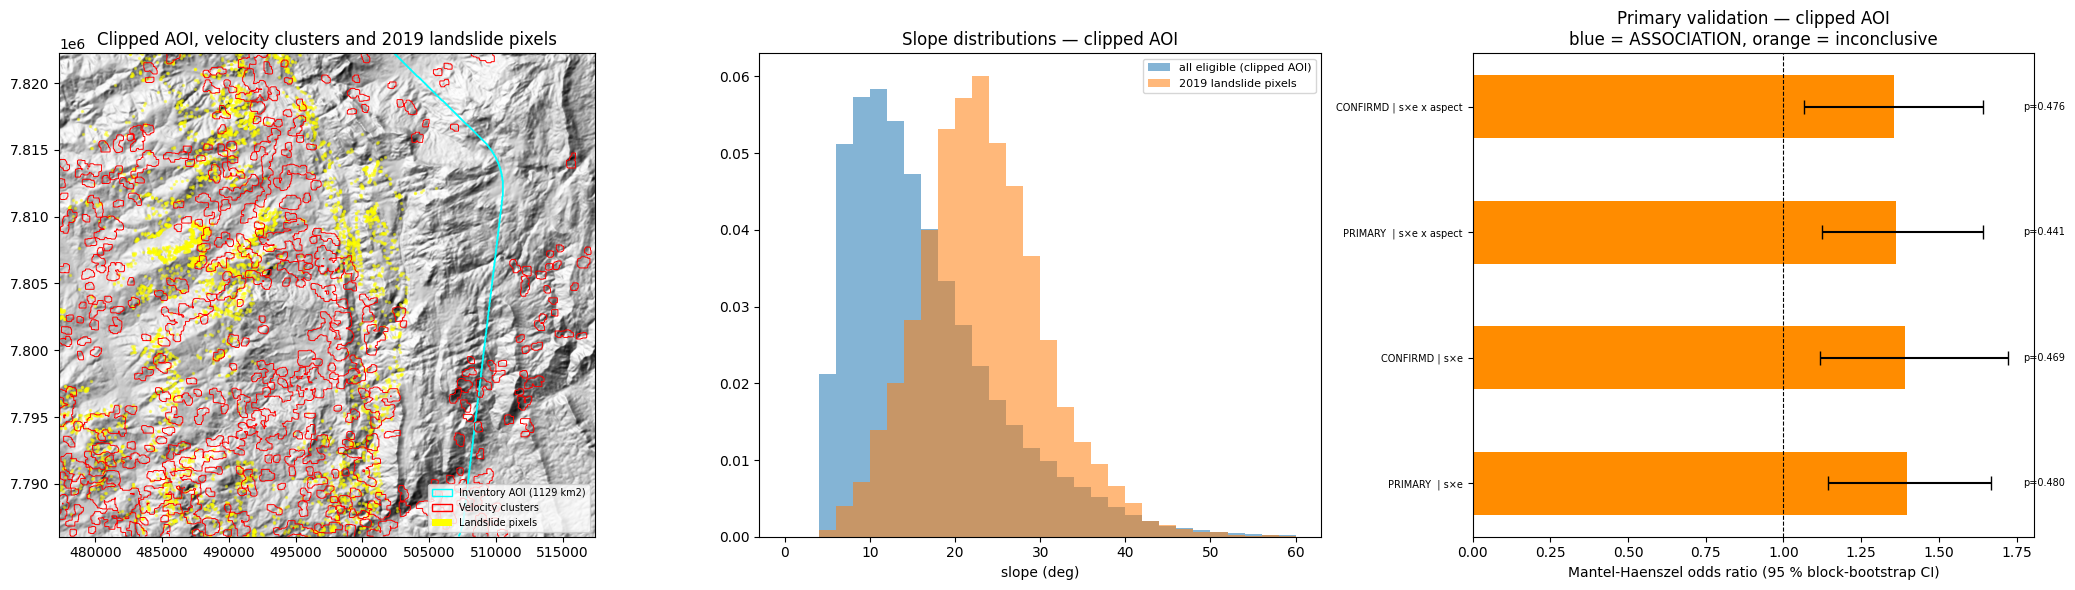

[PASS] Copied to Google Drive/chimanimani_stage4v3

COPY-PASTE BLOCK FOR METHODS / RESULTS

Validation (Stage 4 v3 — 2026-10-08)
--------------------------------------------------------------
Detector: K = 2.5 sigma, background block = 50 px, minimum cluster area = 20 px,
  slope threshold = 5.0 deg, dilation buffer = 3 px.

Analysis AOI: convex hull of 5599 source points within the MintPy footprint, buffered by
  5 km -> 1129 km2 (78% of the 1451 km2 footprint).
  The AOI is derived from the inventory and was chosen after a full-footprint analysis; both are reported.

Primary association (clipped AOI; shift-permutation test, 999 permutations, min shift 3 km):
  slope x elevation strata          : MH OR = 1.40, 95 % block-bootstrap CI [1.14, 1.67], p = 0.4800
  + aspect-quadrant strata          : MH OR = 1.36, 95 % block-bootstrap CI [1.12, 1.64], p = 0.4410
  (odds of a 2019 source pixel are about 1.4 times higher in flagged than in unflagged
   terrain-matched pixels; this is an odds

In [ ]:
# ===== CELL 6: save outputs (v3) =====

CAVEAT = (
    f"Temporal gap: inventory=March 2019 (Cyclone Idai), InSAR=Oct2025-Sep2026 (6-yr gap). "
    f"Retrospective coincidence test only, not prospective prediction. "
    f"AOI: inventory hull + {HULL_BUFFER_M/1000:.0f} km buffer = {aoi_km2:.0f} km2 "
    f"({aoi_km2/full_km2:.0%} of {full_km2:.0f} km2 MintPy footprint); the AOI is derived from the inventory "
    f"itself and was adopted after a full-footprint analysis (v1) gave p=0.076 - report both. "
    f"Scale mismatch: pixel {abs(x_step):.0f}m x {abs(y_step):.0f}m >> median scar ~600 m2. "
    f"Odds ratio, not risk ratio."
)

res_df = pd.DataFrame(RESULTS); res_df['caveat'] = CAVEAT
SENS['caveat'] = CAVEAT
res_df.to_csv(f'{OUT_DIR}/validation_primary.csv', index=False)
SENS.to_csv(f'{OUT_DIR}/validation_sensitivity.csv', index=False)
pd.DataFrame(LR_ROWS).to_csv(f'{OUT_DIR}/susceptibility_cv.csv', index=False)
ok("CSVs saved")

aoi_tif = f'{OUT_DIR}/aoi_mask.tif'
with rasterio.open(aoi_tif, 'w', driver='GTiff', dtype='uint8', count=1, width=nx_g, height=ny_g,
                   crs=f'EPSG:{epsg}', transform=transform, compress='lzw') as dst:
    dst.write(aoi_mask.astype('uint8')[None, :, :])
ok(f"AOI mask GeoTIFF: {aoi_tif}")

# ── Figures ───────────────────────────────────────────────────────────────
from matplotlib.patches import Patch
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

ax = axes[0]
ext = [x0, x0 + nx_g * x_step, y0 + ny_g * y_step, y0]
ax.imshow(hs, cmap='gray', extent=ext, origin='upper')
ax.contour(aoi_mask, levels=[0.5], colors='cyan', linewidths=1.3, extent=ext, origin='upper')
ax.contour(F_vel, levels=[0.5], colors='red', linewidths=0.7, extent=ext, origin='upper')
rr, cc_ = np.nonzero(L & elig_clipped)
ax.scatter(x0 + cc_ * x_step, y0 + rr * y_step, s=2, c='yellow', alpha=0.4)
ax.legend(handles=[Patch(fc='none', ec='cyan', label=f'Inventory AOI ({aoi_km2:.0f} km2)'),
                   Patch(fc='none', ec='red', label='Velocity clusters'),
                   Patch(fc='yellow', label='Landslide pixels')], fontsize=7, loc='lower right')
ax.set_title('Clipped AOI, velocity clusters and 2019 landslide pixels')

ax = axes[1]
bins = np.arange(0, 62, 2)
ax.hist(slope[elig_clipped], bins=bins, density=True, alpha=0.55, label='all eligible (clipped AOI)')
ax.hist(slope[L & elig_clipped], bins=bins, density=True, alpha=0.55, label='2019 landslide pixels')
ax.set_xlabel('slope (deg)'); ax.legend(fontsize=8)
ax.set_title('Slope distributions — clipped AOI')

ax = axes[2]
if RESULTS:
    ors = np.array([r['mh_or'] for r in RESULTS]); los = np.array([r['ci_lo'] for r in RESULTS])
    his = np.array([r['ci_hi'] for r in RESULTS]); ps = [r['perm_p'] for r in RESULTS]
    labs = [f"{r['analysis'][:8]} | {r['strata'].replace('slope x elev','s×e')}" for r in RESULTS]
    cols = ['steelblue' if r['verdict'] == 'ASSOCIATION' else 'darkorange' for r in RESULTS]
    ypos = np.arange(len(ors))
    ax.barh(ypos, ors, xerr=[ors - los, his - ors], color=cols, height=0.5, capsize=5)
    for y_, p_ in zip(ypos, ps):
        ax.text(np.nanmax(his) + 0.05, y_, f'p={p_:.3f}', va='center', fontsize=7)
    ax.axvline(1, color='black', linestyle='--', linewidth=0.8)
    ax.set_yticks(ypos); ax.set_yticklabels(labs, fontsize=7)
    ax.set_xlabel('Mantel-Haenszel odds ratio (95 % block-bootstrap CI)')
    ax.set_title('Primary validation — clipped AOI\nblue = ASSOCIATION, orange = inconclusive')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/validation_overview_v3.png', dpi=130)
plt.show()

if mount_drive():
    shutil.copytree(OUT_DIR, os.path.join(DRIVE_ROOT, 'chimanimani_stage4v3'), dirs_exist_ok=True)
    ok("Copied to Google Drive/chimanimani_stage4v3")
else:
    warn("Drive unavailable: outputs are on the Colab disk only")

# ── Copy-paste report block ───────────────────────────────────────────────
print("\n" + "=" * 72); print("COPY-PASTE BLOCK FOR METHODS / RESULTS"); print("=" * 72)
def _pick(strat):
    return next(r for r in RESULTS if 'PRIMARY' in r['analysis'] and r['strata'] == strat)
r_b, r_a = _pick('slope x elev'), _pick('slope x elev x aspect')
pix_area = abs(x_step) * abs(y_step)
print(f"""
Validation (Stage 4 v3 — {__import__('datetime').date.today()})
--------------------------------------------------------------
Detector: K = {K_VEL} sigma, background block = {BG_BLOCK_PX} px, minimum cluster area = {MIN_PIXELS} px,
  slope threshold = {SLOPE_MIN_DEG} deg, dilation buffer = {BUFFER_PX} px.

Analysis AOI: convex hull of {inside.sum()} source points within the MintPy footprint, buffered by
  {HULL_BUFFER_M/1000:.0f} km -> {aoi_km2:.0f} km2 ({aoi_km2/full_km2:.0%} of the {full_km2:.0f} km2 footprint).
  The AOI is derived from the inventory and was chosen after a full-footprint analysis; both are reported.

Primary association (clipped AOI; shift-permutation test, {N_PERM} permutations, min shift {MIN_SHIFT_PX*abs(x_step)/1000:.0f} km):
  slope x elevation strata          : MH OR = {r_b['mh_or']:.2f}, 95 % block-bootstrap CI [{r_b['ci_lo']:.2f}, {r_b['ci_hi']:.2f}], p = {r_b['perm_p']:.4f}
  + aspect-quadrant strata          : MH OR = {r_a['mh_or']:.2f}, 95 % block-bootstrap CI [{r_a['ci_lo']:.2f}, {r_a['ci_hi']:.2f}], p = {r_a['perm_p']:.4f}
  (odds of a 2019 source pixel are about {r_a['mh_or']:.1f} times higher in flagged than in unflagged
   terrain-matched pixels; this is an odds ratio.)

Sensitivity: {SHARE_SIG['slope x elev']:.0%} (slope x elev) and {SHARE_SIG['slope x elev x aspect']:.0%} (+ aspect) of the
  detector-grid rows have a CI lower bound > 1. Time-series detector not estimable (too few flagged case pixels).

Key caveats
  * Temporal gap: Idai inventory March 2019; InSAR Oct 2025 - Sep 2026 (~6 yr). Retrospective coincidence
    test, not prospective prediction.
  * Scale: pixel area {pix_area:.0f} m2 >> median depletion-zone scar ~600 m2. Hillslope scale only.
""")
print("=" * 72)